## ISOM4030 Lab 3 (Part 1) - Summary and Visualization of Gradient Descent

In [1]:
# If you want to enable matplotlib's interactive features
# install jupyter-matplotlib (a.k.a. ipympl) via pip or conda.
! pip install ipympl --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 515.7/515.7 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 47.3 MB/s eta 0:00:00


Restart runtime to continue

In [1]:
from google.colab import output
output.enable_custom_widget_manager()

# Enable the `widget` backend.

%matplotlib widget

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

import pandas as pd
import numpy as np

from lab3_utils import plt_stationary, plt_update_onclick, plt_gradient_descent_path

%config InlineBackend.figure_format="retina"

In [4]:
# extract 6 pairs of data from the housing prices dataset
# x_train is storing values of house size (1000 sqrft)
# y_train is storing values of house price (in thousands of dollars)

x_train = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y_train = np.array([250, 300, 480, 430, 630, 730])

## 3D Cost Function Visualization

Let's see how cost varies with respect to *both* `w` and `b` by plotting in 3D or using a contour plot.   

Because some of the plotting in this course can be quite involved, we'll provide you the plotting routines that you can readily use (e.g., in `lab3_utils.py` for lab 3). Although you are not required to understand them for completing the course, it can be instructive to read through the code to become familiar with the plotting methods.


Run the code cell below to create 3 plots, which give you 3 different perspectives of looking at a linear regression fitting process.



In the contour plot, click on a point to select `w` and `b` to achieve the lowest cost. Use the contours to guide your selections (values of approximately $w=209$ and $b=2.4$ provide the lowest cost).  Note that it can take a few seconds to update the graph.

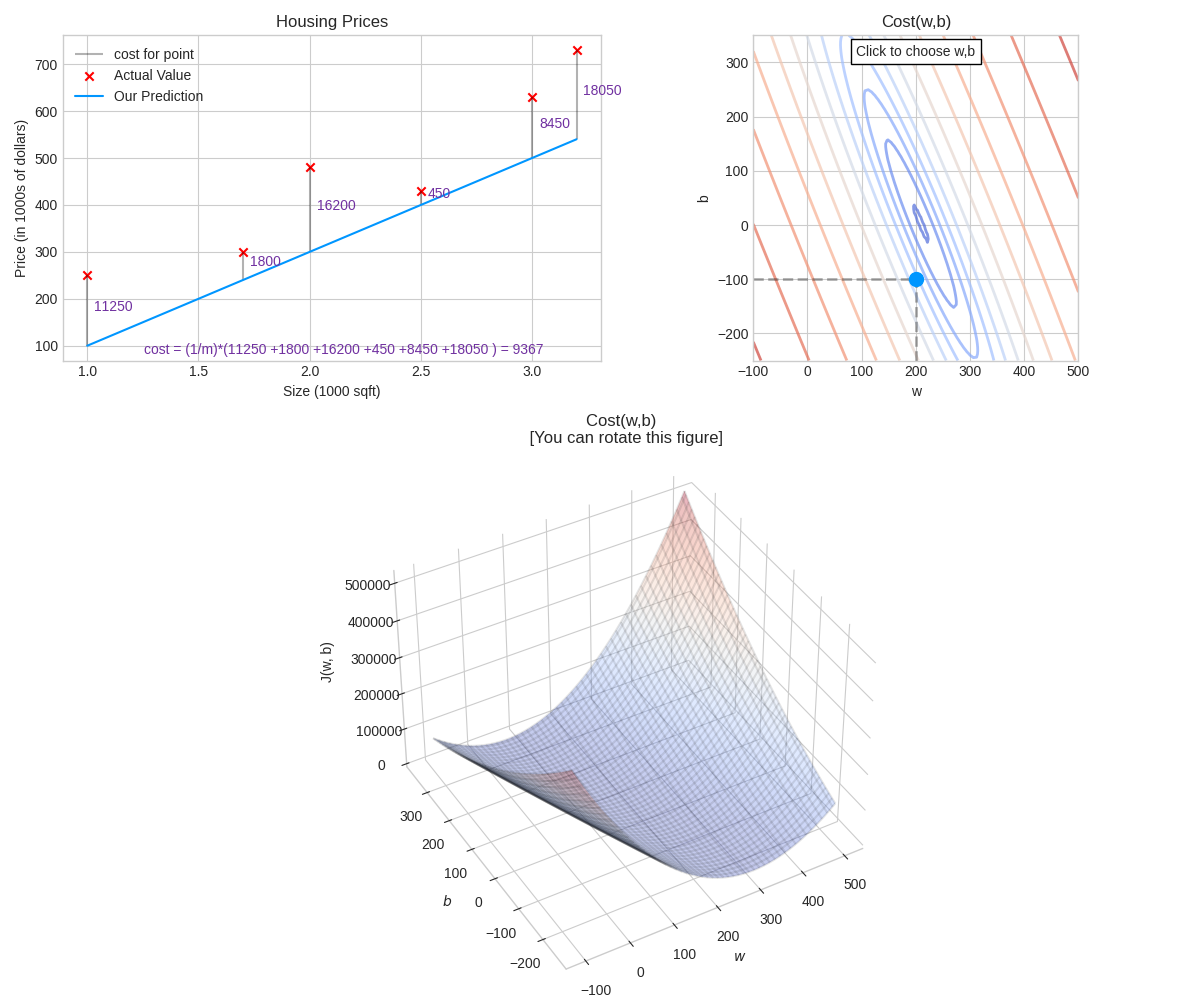

In [5]:
plt.close('all')
fig, ax, dyn_items = plt_stationary(x_train, y_train)
updater = plt_update_onclick(fig, ax, x_train, y_train, dyn_items)


## Gradient Descent Summary


So far in this course, you have developed a linear model that predicts $f_{w,b}(x^{(i)})$:
$$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{1}$$

In linear regression, you utilize input training data to fit the parameters $w$, $b$ by minimizing a measure of the error between our predictions $f_{w,b}(x^{(i)})$ and the actual data $y^{(i)}$.

The measure is called the ***cost*** or ***loss***, $J(w,b)$. In training you measure the cost over all of our training samples $x^{(i)},y^{(i)}$
$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2\tag{2}$$


In lecture, *gradient descent* for a one-variable linear regression model is described as:

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline
\;  w &= w -  \alpha \frac{\partial J(w,b)}{\partial w} \tag{3}  \; \newline
 b &= b -  \alpha \frac{\partial J(w,b)}{\partial b}  \newline \rbrace
\end{align*}$$
where parameters $w$, $b$ should be updated simultaneously.  


Here *simultaniously* means that you calculate the partial derivatives for all the parameters before updating any of the parameters.


Using calculus to derive the gradient expression gives:

$$
\begin{align}
\frac{\partial J(w,b)}{\partial w}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)} \tag{4}\\
  \frac{\partial J(w,b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) \tag{5}\\
\end{align}
$$



**<font color='steelblue' > Exercise</font>**:

Complete the code below to implement gradient descent algorithm for single feature and generate a plot as below:

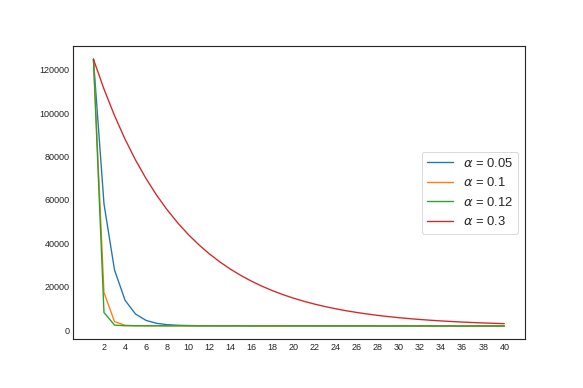

In [ ]:
# gradient descent function - inputs:
# g (input function), alpha (steplength parameter), max_its (maximum number of iterations),

def gradient_descent(x_train, y_train, init_parameters, lr, n_iterations):

  b, w = init_parameters
  weight_history = []; cost_history = []

  for epoch in range(n_iterations):

      # Your code starts here

      weight_history.append((b, w))
      yhat = ________________
      error = ________________
      b_grad = ________________
      w_grad = ________________
      b = ________________
      w = ________________
      cost_history.append((error ** 2).mean() / 2)

      # Your code ends here

  return weight_history, cost_history

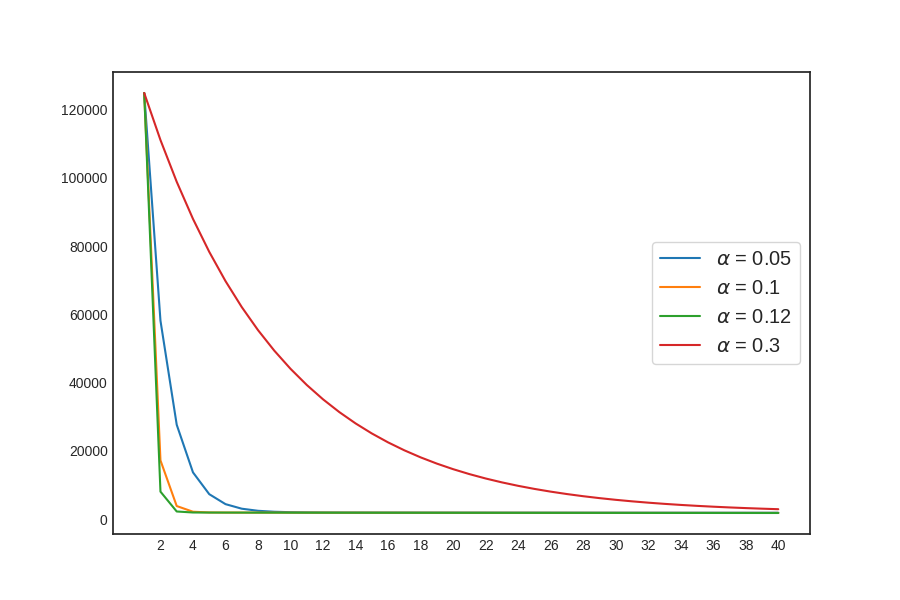

In [ ]:
n_iterations = 40

fig, ax = plt.subplots(1, 1, figsize=(9, 6))

for alpha in [0.05, 0.1, 0.12, 0.3]:
  weight_history, cost_history = gradient_descent(x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  ax.plot(np.arange(1, 41), cost_history, label=r"$\alpha$" + f" = {alpha}")

ax.legend(loc="center right", fontsize="x-large", frameon=True)

ax.set(xticks=range(2, 41, 2))
plt.show()

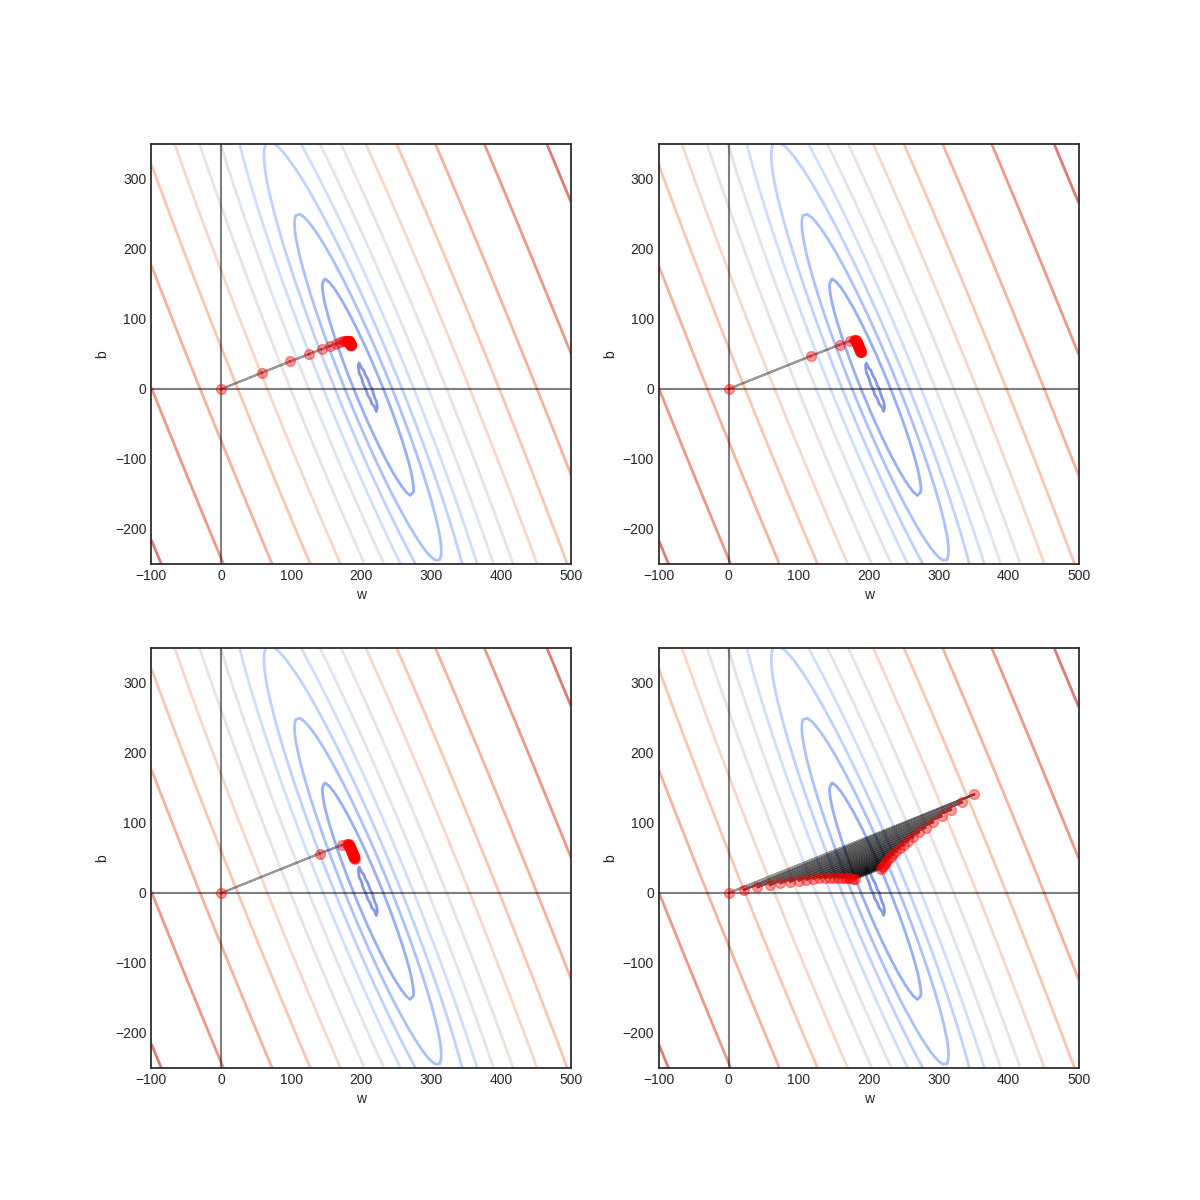

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 12))
w_range = np.array([200-300, 200+300])
b_range = np.array([50-300, 50+300])

for ax, alpha in zip(ax.flat, [0.05, 0.1, 0.12, 0.3]):
  weight_history, cost_history = gradient_descent(x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  plt_gradient_descent_path(fig, ax, x_train, y_train, weight_history, w_range, b_range)

## Feature Scaling


You can standardize your dataset using the scikit-learn object [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).


Apply ***fit()*** to compute the mean and std to be used for scaling. It requires a 2D array as argument. Apply ***transform()*** to perform standardization by centering and scaling.



In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


scaler = StandardScaler()
x_tmp = x_train.reshape(-1, 1)    # fit() takes a 2-D array as argument
scaler.fit(x_tmp)
scaled_x_train = scaler.transform(x_tmp).flatten()

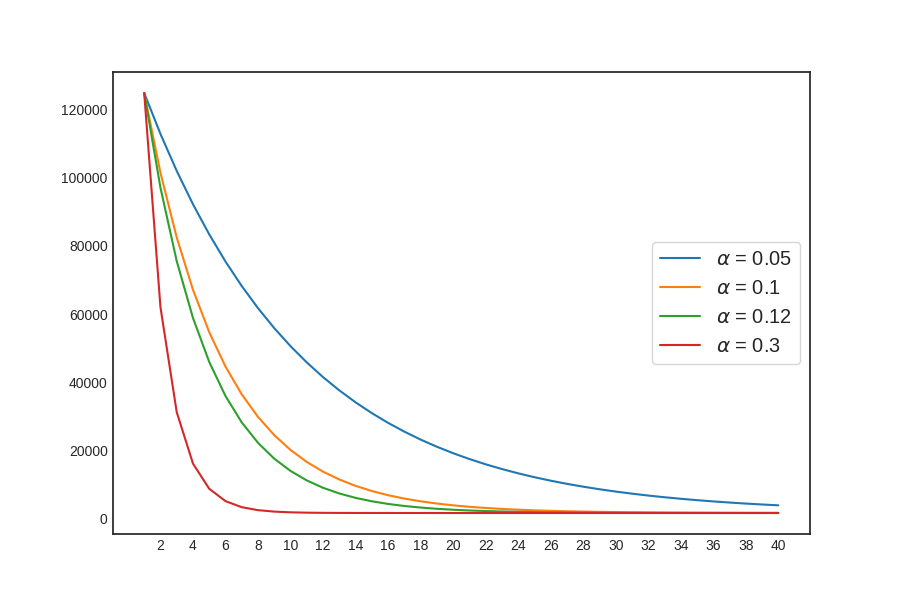

In [ ]:
n_iterations = 40
fig, ax = plt.subplots(1, 1, figsize=(9, 6))

for alpha in [0.05, 0.1, 0.12, 0.3]:
  weight_history, cost_history = gradient_descent(scaled_x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  ax.plot(np.arange(1, 41), cost_history, label=r"$\alpha$" + f" = {alpha}")

ax.legend(loc="center right", fontsize="x-large", frameon=True)

ax.set(xticks=range(2, 41, 2))
plt.show()

In [ ]:
lm = LinearRegression()
lm.fit(scaled_x_train.reshape(-1, 1), y_train)
lm.intercept_, lm.coef_[0]

(469.99999999999994, 158.83398122169453)

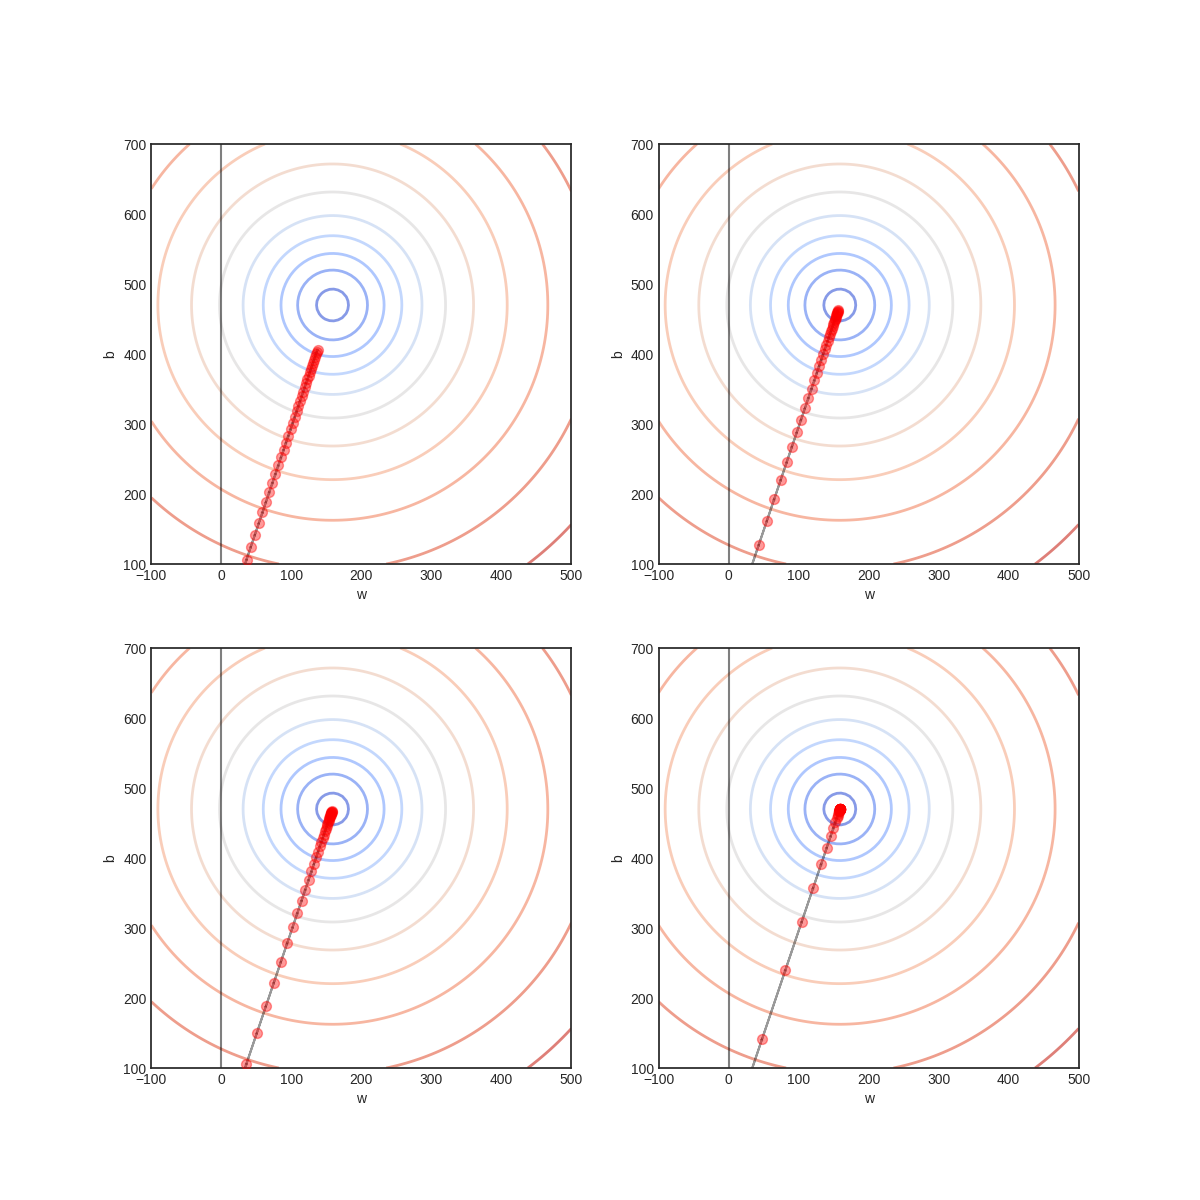

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 12))
w_range = np.array([200-300, 200+300])
b_range = np.array([400-300, 400+300])

# Your code starts here

for ax, alpha in zip(ax.flat, [0.05, 0.1, 0.12, 0.3]):
  weight_history, cost_history = gradient_descent(scaled_x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  plt_gradient_descent_path(fig, ax, scaled_x_train, y_train, weight_history, w_range, b_range)


In [ ]:
x = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y = np.array([250, 300, 480, 430, 630, 730])

w,b,lr = 0,0,0.1

n_iterations = 100

yhat = x * w + b
error = yhat - y
w_grad = (x * error).mean()
b_grad = error.mean()
# equivalently, np.square(error).mean() / 2
Loss = (error ** 2).mean() / 2

for epoch in range(n_iterations):
  # Step 1 - Compute model's predicted output
  yhat = w * x + b
  # Step 2 - Compute the loss using all data points
  # Compute individual errors
  error = yhat - y
  # Compute mean squared error (MSE)
  loss = (error ** 2).mean() / 2
  # Step 3 - Compute gradients for both parameters
  b_grad = error.mean()
  w_grad = (x * error).mean()
  # Step 4 - Update parameters
  b = b - lr * b_grad
  w = w - lr * w_grad
print(b, w)

31.55401925691066 197.47864904161335
